# FastAPI 서빙 실습: 끊긴 SSE 응답을 이어 받는 흐름에서 접근 토큰 하나만 바꾸기

**이 노트북에서 할 일**

1. 05~07절에서 배운 사전 요청·SSE 응답·이어 받기를 한 요청 흐름으로 잇습니다.
2. 교재용 접근 토큰으로 흐름을 끝까지 실행하고, 이어 붙인 글을 끊기지 않은 응답과 견줍니다.
3. 접근 토큰 하나만 틀린 값으로 바꿔 같은 흐름을 실행하고, 두 실행의 단계 기록을 견줍니다.

**준비물** — 이 노트북은 모델을 부르지 않아 API 키가 필요 없습니다.
모델 요청은 0번이고, 비용도 들지 않습니다.
요청은 시험용 클라이언트로 같은 노트북 안에서 보냅니다.
서버 프로그램을 띄우지 않고, 포트를 쓰지 않습니다.
실습 폴더의 파일은 가져오고 읽기만 하며, 쓰는 파일은 없습니다.

첫 셀의 설치에는 몇십 초가 걸릴 수 있습니다.
걸린 시간은 재지 않았습니다.

**기준 버전** — 첫 셀에서 패키지 여섯을 설치합니다.
판은 fastapi 0.135.0, httpx 0.28.1, pydantic 2.12.5, starlette 1.6.0입니다.
실습 앱 파일은 패키지 langgraph 1.2.11과 langchain 1.4.0을 가져옵니다.
여섯 모두 실습 폴더 잠금과 같은 판입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.

다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**실습 방법** — 따로 내는 과제는 없고, 강사와 함께 첫 셀부터 순서대로 실행합니다.
실습 폴더 `labs/part7/ch30-fastapi-serving`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 맨 위 초록 상자 재료에는 출처 http://localhost:5173, 질문 반납 기한, 스레드 web-1, 실행마다 접근 토큰 하나가 적혀 있습니다. 그 아래 파란 상자 넷이 실선으로 차례로 이어집니다. start_flow 사전 요청 07절 첫 요청 05절 단계마다 기록 한 줄, 앞 사건 둘만 받고 끊김 06절 노트북 2절과 같은 자리, resume_flow 번호가 있을 때만 사전 요청 07절 이어 받기 06절 단계마다 기록 한 줄, 판정 ended_with_done 06절 join_tokens 04절입니다. start_flow와 resume_flow에서 오른쪽 회색 상자 CORS 층 앱 19~26행 사전 요청에 바로 답함으로 점선이 가고, 회색 상자에서 초록 상자 실습 앱 chat_stream 제공 함수 require_token get_resume_index로 점선이 가는 그림](attachment:10-1-세-절-기능을-이은-요청-흐름.png)

위에서 아래로 읽습니다.
초록 상자는 우리가 보낸 재료와 실습 앱 파일의 처리 함수입니다.
파란 상자는 이 절 노트북에서 만든 함수와 흐름의 자리이고, 상자 안의 절 번호는 그 기능을 배운 절입니다.
실선은 흐름의 차례이고, 점선은 실습 앱으로 보내는 요청입니다.
회색 상자인 CORS 층은 사전 요청에 바로 답하고, 그 밖의 요청만 실습 앱으로 넘깁니다.
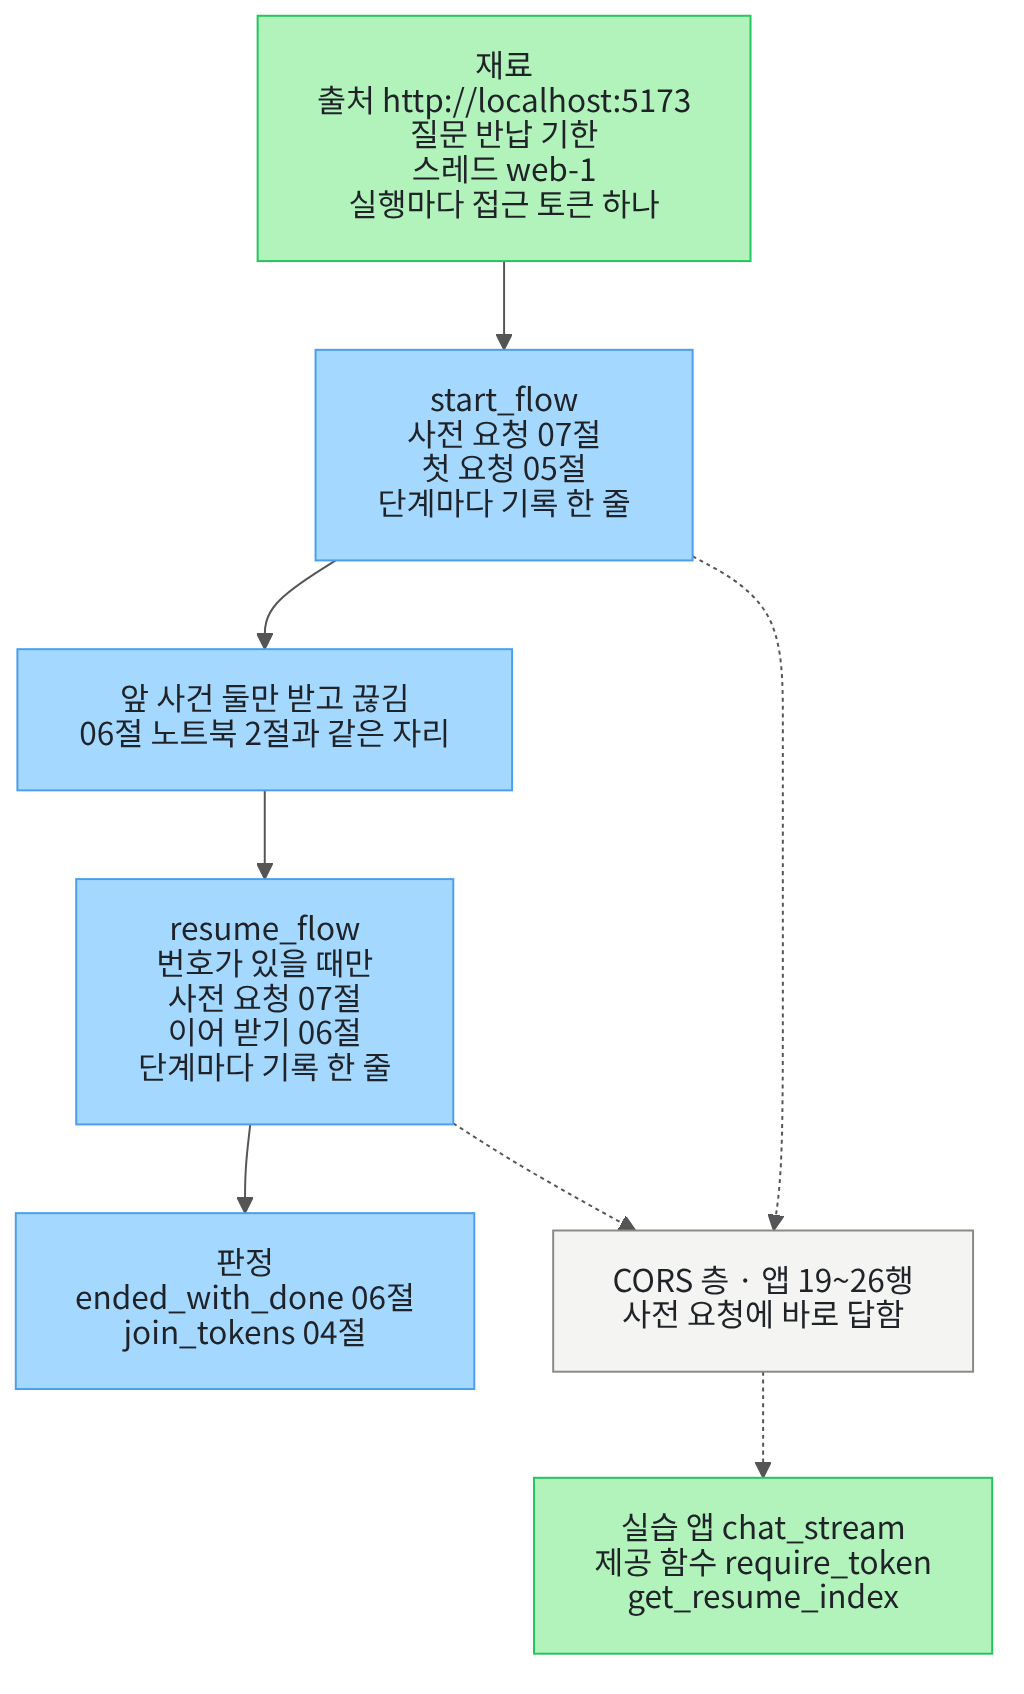

## 1. 준비

이 절은 이 챕터의 실습입니다.
01~09절에서 쓴 라이브러리 이름과 문법만 쓰고, 흐름을 잇는 함수만 이 절에서 새로 만듭니다.
제목의 서빙은 만든 에이전트를 웹 앱에 올려, 요청에 답하게 하는 일입니다.
첫 셀은 07·08절과 같은 패키지 여섯을 설치하고, 설치된 판 번호를 출력합니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "fastapi==0.135.0" "httpx==0.28.1" "pydantic==2.12.5" "starlette==1.6.0" "langgraph==1.2.11" "langchain==1.4.0"
from importlib.metadata import version

print("fastapi:", version("fastapi"))
print("httpx:", version("httpx"))
print("pydantic:", version("pydantic"))
print("starlette:", version("starlette"))
print("langgraph:", version("langgraph"))
print("langchain:", version("langchain"))

Note: you may need to restart the kernel to use updated packages.


fastapi: 0.135.0
httpx: 0.28.1
pydantic: 2.12.5
starlette: 1.6.0
langgraph: 1.2.11
langchain: 1.4.0


**결과 읽기** — 출력 줄 `fastapi: 0.135.0`부터 `langchain: 1.4.0`까지 여섯 줄이 보입니다.
07·08절과 같은 패키지를 같은 판으로 설치했습니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
04·06·07절에서 배운 함수 일곱은 도구 파일 `serve_tools.py`에서 가져옵니다.

In [2]:
# 이 절에서 쓸 이름을 가져옵니다(os는 Python에 들어 있는 모듈입니다)
import os
from fastapi.testclient import TestClient
# 04·06·07절에서 배운 함수 일곱은 도구 파일에서 가져옵니다
from serve_tools import ended_with_done, event_names, header_or_none, join_tokens, last_event_id, read_events, token_values

print("가져온 이름:", "TestClient")
print("도구 파일에서 가져온 함수:", "ended_with_done, event_names, header_or_none, join_tokens, last_event_id, read_events, token_values")

가져온 이름: TestClient
도구 파일에서 가져온 함수: ended_with_done, event_names, header_or_none, join_tokens, last_event_id, read_events, token_values


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수:` 뒤에 함수 일곱이 보입니다.
함수 `join_tokens`는 04절, `header_or_none`은 07절에서 배웠고, 나머지 다섯은 06절에서 배웠습니다.
06절 함수 `last_event_id`와 07절 함수 `header_or_none`은 이 절부터 도구 파일에 있습니다.
두 함수는 그 절 노트북의 셀을 주석과 본문 그대로 옮겼습니다.

앞에서 배운 함수는 `serve_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

다음 셀은 01절 2절과 같은 파일 위치 셀로, 후보 셋 가운데 실습 폴더를 고릅니다.

In [3]:
# 노트북을 연 자리에서 본 실습 폴더의 위치를 후보 셋 가운데에서 고릅니다
candidates = ["..", ".", "labs/part7/ch30-fastapi-serving"]
lab_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/agent_service/schemas.py"):
        lab_path = candidate
        break
print("실습 폴더를 찾았는가:", lab_path is not None)
assert lab_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

실습 폴더를 찾았는가: True


**결과 읽기** — 출력 줄 `실습 폴더를 찾았는가: True`가 보입니다.
고른 후보는 연 자리마다 달라서 출력하지 않습니다.
실습 폴더 맨 위에서 연 커널은 이 안내를 보기 전에, 앞 셀의 도구 파일 가져오기에서 먼저 멈춥니다.

다음 셀은 작업 폴더를 실습 폴더로 옮긴 뒤, 앱 파일에서 앱 객체 `app`을 가져옵니다.
02절에서 본 재정의 딕셔너리의 키 수도 함께 출력합니다.

In [4]:
# 작업 폴더를 실습 폴더로 옮기고, 앱 파일에서 앱 객체를 가져옵니다
os.chdir(lab_path)
from agent_service.app import app
print("가져온 앱 객체의 종류:", type(app).__name__)
print("재정의 딕셔너리의 키 수:", len(app.dependency_overrides))

가져온 앱 객체의 종류: FastAPI
재정의 딕셔너리의 키 수: 0


**결과 읽기** — 출력 줄 `재정의 딕셔너리의 키 수: 0`이 보입니다.
바꿔 낀 제공 함수가 하나도 없어, 실습 앱의 제공 함수가 그대로 불립니다.
이 절은 재정의를 쓰지 않습니다.

## 2. 오늘의 상황과 재료

도서관 웹 화면 하나가 실습 앱에 질문을 보내고, 답을 SSE 사건으로 받습니다.
화면의 출처는 `http://localhost:5173`이고, 앱이 허용 출처로 적은 값입니다.
화면은 SSE 사건 둘을 받은 뒤 연결이 끊겨, 받은 마지막 사건 번호로 이어 받습니다.
다음 셀은 이 흐름이 요청을 보낼 처리 함수 `chat_stream`의 머리 99~105행을 출력합니다.

In [5]:
# 앱 파일을 글로 읽어, SSE 처리 함수 chat_stream의 머리 99~105행을 출력합니다
first_line = 99
last_line = 105
with open("agent_service/app.py", encoding="utf-8") as app_file:
    app_lines = app_file.read().splitlines()
print("줄 번호 | 줄")
for index in range(first_line - 1, last_line):
    print(index + 1, "|", app_lines[index])

줄 번호 | 줄
99 | @app.post("/v1/chat/stream", response_class=EventSourceResponse)
100 | async def chat_stream(
101 |     body: ChatRequest,
102 |     runtime: AgentDep,
103 |     _token: AuthDep,
104 |     timeout: TimeoutDep,
105 |     start: ResumeIndexDep,


**결과 읽기** — 라벨 줄 아래 99~105행이 처리 함수 `chat_stream`의 머리입니다.
103행의 `_token: AuthDep`은 02·07절에서 본 제공 함수 `require_token`으로 접근 토큰을 검사합니다.
105행의 `start: ResumeIndexDep`은 06절의 제공 함수로, 요청 머리 `Last-Event-ID`에서 이어 받을 자리를 읽습니다.
102행과 104행은 02절에서 본 그래프와 시간 제한의 제공 함수입니다.
라이브러리는 이 제공 함수들을 처리 함수 몸통보다 먼저 부릅니다.

07절에서 본 것처럼, 앱 19~26행의 CORS 층은 이보다도 앞에서 요청을 봅니다.
사전 요청이면 CORS 층이 앱으로 넘기지 않고 바로 답합니다.

다음 셀은 두 실행이 함께 쓸 재료를 만듭니다.
모두 실행 전에 정한 값이고, 출력 라벨에 어디서 온 값인지 적었습니다.

In [6]:
# 두 실행이 함께 쓸 재료를 만듭니다 — 모두 실행 전에 정한 값입니다
client = TestClient(app)
page_origin = "http://localhost:5173"
question_body = {"question": "반납 기한을 알려 주세요", "thread_id": "web-1"}
good_token = "Bearer local-demo-token"
print("화면의 출처(앱 21행의 허용 출처):", page_origin)
print("질문 본문(스레드 이름 web-1은 이 절에서 정함):", question_body)
print("실행 1의 접근 토큰(앱 57행의 교재용 값):", good_token)

화면의 출처(앱 21행의 허용 출처): http://localhost:5173
질문 본문(스레드 이름 web-1은 이 절에서 정함): {'question': '반납 기한을 알려 주세요', 'thread_id': 'web-1'}
실행 1의 접근 토큰(앱 57행의 교재용 값): Bearer local-demo-token


**결과 읽기** — 출력 줄 `화면의 출처(앱 21행의 허용 출처): http://localhost:5173`이 보입니다.
질문 「반납 기한을 알려 주세요」는 03~07절과 같은 질문입니다.
스레드 이름 `web-1`은 이 절에서 정한 이름이고, 사건 번호의 앞머리가 됩니다.
접근 토큰은 02·07절에서 쓴 교재용 값이고, 실행 2에서만 바꿉니다.

## 3. 흐름의 부품

흐름은 요청 두 가지를 보냅니다.
하나는 07절의 사전 요청이고, 다른 하나는 접근 토큰을 실은 질문 요청입니다.
다음 셀은 사전 요청을 보내는 함수를 정의합니다.

In [7]:
# 허용 출처 화면이 보낼 사전 요청을 요청 주소 /v1/chat/stream에 보내고, 응답을 내놓습니다
def send_preflight(header_names):
    # 요청 머리 이름은 실제 요청에 실을 머리를 쉼표로 이어 적은 글입니다(07절과 같은 모양)
    preflight_headers = {"Origin": page_origin, "Access-Control-Request-Method": "POST",
                         "Access-Control-Request-Headers": header_names}
    return client.options("/v1/chat/stream", headers=preflight_headers)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
인자 `header_names`에는 실제 요청에 실을 요청 머리 이름을 쉼표로 이어 적은 글을 넣습니다.
함수는 2절에서 만든 `client`와 `page_origin`을 그대로 씁니다.

다음 셀은 출처와 접근 토큰을 요청 머리에 실어 질문을 보내는 함수를 정의합니다.
이어 받을 사건 번호가 있으면, 06절처럼 요청 머리 `Last-Event-ID`도 싣습니다.

In [8]:
# 출처와 접근 토큰을 요청 머리에 실어 질문을 보내고, 응답을 내놓습니다
def send_question(token, resume_id):
    request_headers = {"Origin": page_origin, "Authorization": token}
    # 이어 받을 사건 번호가 있으면 06절처럼 요청 머리 Last-Event-ID도 싣습니다
    if resume_id is not None:
        request_headers = {"Origin": page_origin, "Authorization": token, "Last-Event-ID": resume_id}
    return client.post("/v1/chat/stream", json=question_body, headers=request_headers)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
인자 `resume_id`가 `None`이면 요청 머리가 둘이고, 사건 번호가 있으면 셋입니다.
질문 본문은 늘 2절의 `question_body`입니다.

다음 셀은 응답을 칸 딕셔너리 목록으로 읽는 함수를 정의합니다.
오류 응답의 본문은 SSE 사건이 아니라 JSON 글이라, 상태 코드가 200일 때만 읽습니다.

In [9]:
# 응답의 상태 코드가 200이면 본문을 칸 딕셔너리 목록으로 읽고, 아니면 빈 목록을 내놓습니다
def events_of(response):
    # 401 같은 오류 응답의 본문은 SSE 사건이 아니라 JSON 글이라 읽지 않습니다
    if response.status_code == 200:
        return read_events(response.text)
    return []

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `read_events`는 06절에서 배운 함수로, 본문 글을 SSE 사건마다 칸 딕셔너리로 바꿉니다.
상태 코드가 200이 아니면 빈 목록을 내놓습니다.

다음 셀은 부품을 한 번 시험합니다.
끊기지 않은 요청을 보내, 뒤에서 견줄 기준 응답을 만듭니다.

In [10]:
# 부품을 한 번 시험합니다 — 끊기지 않은 요청을 보내, 뒤에서 견줄 기준 응답을 만듭니다
full_response = send_question(good_token, None)
full_events = events_of(full_response)
full_text = join_tokens(token_values(full_events))
print("상태 코드:", full_response.status_code)
print("허용 출처:", header_or_none(full_response, "access-control-allow-origin"))
print("사건 이름:", event_names(full_events))
print("이어 붙인 글:", full_text)

상태 코드: 200
허용 출처: http://localhost:5173
사건 이름: ['token', 'token', 'token', 'token', 'token', 'token', 'done']
이어 붙인 글: 질문을 확인했습니다: 반납 기한을 알려 주세요 


**결과 읽기** — 출력 줄 `허용 출처: http://localhost:5173`이 보입니다.
SSE 응답에도 CORS 층이 허용 출처 응답 머리를 붙였습니다.
사건 이름은 token 여섯 뒤에 `done`으로, 05·06절과 같은 차례입니다.
출력 줄 `이어 붙인 글:`의 글이 뒤에서 견줄 기준 응답의 글입니다.

## 4. 단계 기록

흐름이 단계마다 무엇을 받았는지 보려면 기록이 필요합니다.
다음 셀은 단계 이름과 응답을 받아, 기록 목록에 한 줄을 더하는 함수를 정의합니다.
한 줄에는 상태 코드와 허용 출처를 적습니다.

In [11]:
# 단계 이름과 응답을 받아, 상태 코드와 허용 출처 응답 머리를 기록 목록에 한 줄로 더합니다
def record_step(log_rows, step_name, response):
    allowed = header_or_none(response, "access-control-allow-origin")
    log_rows.append([step_name, response.status_code, allowed])

**결과 읽기** — 정의 셀이라 출력이 없습니다.
기록 한 줄은 단계 이름, 상태 코드, 허용 출처를 담은 목록입니다.
허용 출처는 07절 함수 `header_or_none`으로 읽어, 응답 머리가 없으면 `None`이 됩니다.

다음 셀은 기록 목록을 표 모양으로 출력하는 함수를 정의합니다.

In [12]:
# 기록 목록을 「단계 | 상태 코드 | 허용 출처」 표 모양으로 한 줄씩 출력합니다
def print_log(log_rows):
    print("단계 | 상태 코드 | 허용 출처")
    for row in log_rows:
        print(row[0], "|", row[1], "|", row[2])

**결과 읽기** — 정의 셀이라 출력이 없습니다.
라벨 줄 다음에, 기록 한 줄이 출력 한 줄이 됩니다.

## 5. 조립

부품을 흐름의 차례대로 잇습니다.
흐름이 길어 함수 둘로 나눴습니다.
다음 셀은 흐름의 앞 절반으로, 사전 요청과 첫 요청을 보냅니다.

In [13]:
# 흐름의 앞 절반 — 사전 요청(07절)을 보낸 뒤, 접근 토큰을 실은 첫 요청(05절)을 보내고 그 응답을 내놓습니다
def start_flow(token, log_rows):
    preflight = send_preflight("Authorization, Content-Type")
    record_step(log_rows, "사전 요청", preflight)
    first_response = send_question(token, None)
    record_step(log_rows, "첫 요청", first_response)
    return first_response

**결과 읽기** — 정의 셀이라 출력이 없습니다.
사전 요청의 요청 머리 이름은 07절과 같은 `Authorization, Content-Type`입니다.
첫 요청은 이어 받을 번호가 없어 `None`을 넘깁니다.
두 요청 모두 기록 목록에 한 줄씩 남기고, 첫 요청의 응답을 내놓습니다.

다음 셀은 흐름의 뒤 절반을 정의합니다.
받은 사건에 번호가 있으면, 요청 머리 이름에 `Last-Event-ID`를 더한 사전 요청을 한 번 더 보냅니다.
그다음 그 번호로 이어 받고, 받은 사건과 이어 받은 사건을 이은 목록을 내놓습니다.

In [14]:
# 흐름의 뒤 절반 — 받은 마지막 사건 번호가 있으면 사전 요청을 한 번 더 보내고 이어 받습니다(06절)
def resume_flow(token, received, log_rows):
    resume_id = last_event_id(received)
    # 받은 사건 번호가 없으면 이어 받을 자리가 없어, 받은 목록을 그대로 내놓습니다
    if resume_id is None:
        return received
    preflight = send_preflight("Authorization, Content-Type, Last-Event-ID")
    record_step(log_rows, "사전 요청(이어 받기)", preflight)
    resumed_response = send_question(token, resume_id)
    record_step(log_rows, "이어 받기", resumed_response)
    return received + events_of(resumed_response)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
받은 사건이 하나도 없으면 함수 `last_event_id`가 `None`을 내놓아, 이어 받기 단계를 보내지 않습니다.

이어 받기 요청은 요청 머리 `Last-Event-ID`를 더 싣습니다.
07절 출력처럼, 첫 사전 요청의 답에도 허용 요청 머리 `Last-Event-ID`가 이미 들어 있습니다.
브라우저는 그 답을 담아 두면, 정한 시간 안에는 사전 요청을 다시 보내지 않을 수 있습니다.
이 흐름은 담아 둔 답이 없는 경우를 흉내 내어, 그 이름을 적은 사전 요청을 한 번 더 보냅니다.

## 6. 실행 1 — 교재용 접근 토큰

실행 1은 2절의 재료 그대로 흐름을 끝까지 실행합니다.
첫 요청에서 앞 사건 둘만 받고 끊겼다고 보며, 06절 노트북 2절과 같은 자리입니다.
실행 전에 예상해 봅니다.
기록 목록에는 몇 단계가 남고, 모두 200일까요?

In [15]:
# 실행 1 — 교재용 접근 토큰으로 흐름을 끝까지 실행하고, 단계 기록을 표로 출력합니다
run1_log = []
run1_first = start_flow(good_token, run1_log)
# 첫 요청에서 앞 사건 둘까지 받고 연결이 끊겼다고 봅니다(06절 2절과 같은 자리)
run1_received = events_of(run1_first)[0:2]
run1_events = resume_flow(good_token, run1_received, run1_log)
print_log(run1_log)

단계 | 상태 코드 | 허용 출처
사전 요청 | 200 | http://localhost:5173
첫 요청 | 200 | http://localhost:5173
사전 요청(이어 받기) | 200 | http://localhost:5173
이어 받기 | 200 | http://localhost:5173


**결과 읽기** — 라벨 줄 아래 네 줄이 실행 1의 단계 기록입니다.
사전 요청, 첫 요청, 이어 받기 앞의 사전 요청, 이어 받기가 차례대로 모두 `200`입니다.
네 응답 모두 허용 출처가 `http://localhost:5173`으로, 화면의 출처와 같습니다.
07절의 규칙으로는 화면이 네 응답을 모두 읽을 수 있습니다.

다음 셀은 끊기기 전에 받은 사건과, 이어 받은 뒤 이은 사건을 봅니다.

In [16]:
# 실행 1에서 끊기기 전에 받은 사건과, 이어 받은 뒤 이은 사건을 봅니다
print("끊기기 전에 받은 사건 이름:", event_names(run1_received))
print("끊기기 전에 받은 마지막 사건 번호:", last_event_id(run1_received))
# 이은 목록의 자리 2(셋째 사건)가 이어 받은 첫 사건입니다
print("이어 받은 첫 사건 번호:", run1_events[2]["id"])
print("이은 사건 이름:", event_names(run1_events))

끊기기 전에 받은 사건 이름: ['token', 'token']
끊기기 전에 받은 마지막 사건 번호: web-1:1
이어 받은 첫 사건 번호: web-1:2
이은 사건 이름: ['token', 'token', 'token', 'token', 'token', 'token', 'done']


**결과 읽기** — 출력 줄 `끊기기 전에 받은 마지막 사건 번호: web-1:1`이 보입니다.
이어 받은 첫 사건 번호는 `web-1:2`로, 받은 번호의 바로 다음 자리입니다.
이은 사건 이름은 token 여섯 뒤에 `done`으로, 기준 응답과 같은 차례입니다.

다음 셀은 06절의 방법으로 실행 1을 판정합니다.
마지막 사건이 `done`인지 보고, 이어 붙인 글을 기준 응답의 글과 견줍니다.

In [17]:
# 실행 1을 판정합니다 — 마지막 사건이 done인가(06절)와, 이어 붙인 글이 기준 응답의 글과 같은가
run1_text = join_tokens(token_values(run1_events))
print("마지막 사건이 done인가:", ended_with_done(run1_events))
print("이어 붙인 글:", run1_text)
print("기준 응답의 글과 같은가:", run1_text == full_text)

마지막 사건이 done인가: True
이어 붙인 글: 질문을 확인했습니다: 반납 기한을 알려 주세요 
기준 응답의 글과 같은가: True


**결과 읽기** — 출력 줄 `마지막 사건이 done인가: True`와 `기준 응답의 글과 같은가: True`가 보입니다.
끊긴 뒤 이어 받아도, 같은 낱말이 겹치거나 빠지지 않았습니다.

## 7. 실행 2 — 접근 토큰 하나만 바꿈

실행 2는 값 하나만 바꿔, 접근 토큰을 07절 노트북 2절의 틀린 값 `Bearer wrong-token`으로 둡니다.
출처·질문·끊기는 자리·사전 요청의 머리 이름은 실행 1과 같습니다.
07절에서도 틀린 접근 토큰에는 401이 왔습니다.
새로 볼 것은 흐름의 어느 단계에서 무엇이 달라지는지입니다.

실행 전에 예상해 봅니다.
사전 요청의 상태 코드와 기록 목록의 줄 수는 어떻게 될까요?

In [18]:
# 실행 2 — 값 하나만 바꿉니다: 접근 토큰을 07절에서 쓴 틀린 값으로 두고 같은 흐름을 실행합니다
wrong_token = "Bearer wrong-token"
run2_log = []
run2_first = start_flow(wrong_token, run2_log)
run2_received = events_of(run2_first)[0:2]
run2_events = resume_flow(wrong_token, run2_received, run2_log)
print("실행 2의 접근 토큰(07절 2절의 틀린 값):", wrong_token)
print_log(run2_log)

실행 2의 접근 토큰(07절 2절의 틀린 값): Bearer wrong-token
단계 | 상태 코드 | 허용 출처
사전 요청 | 200 | http://localhost:5173
첫 요청 | 401 | http://localhost:5173


**결과 읽기** — 라벨 줄 아래 두 줄이 실행 2의 단계 기록입니다.
사전 요청은 실행 1과 같이 `200`이고, 첫 요청은 `401`입니다.
401 응답에도 허용 출처 `http://localhost:5173`이 붙어 있습니다.
기록이 두 줄뿐이라, 이어 받기 앞의 사전 요청과 이어 받기는 보내지 않았습니다.

흐름이 보낸 사전 요청에는 요청 머리 `Authorization`이 없습니다.
07절의 사전 요청처럼 출처, 요청 방식, 요청 머리 이름만 실었습니다.
그래서 CORS 층은 접근 토큰과 상관없이 사전 요청에 답했습니다.
접근 토큰 검사는 그 뒤의 첫 요청에서, 처리 함수 앞의 제공 함수가 했습니다.

다음 셀은 첫 요청의 응답 본문과, 끊기기 전에 받은 사건을 봅니다.

In [19]:
# 실행 2의 첫 요청 응답 본문과, 끊기기 전에 받은 사건을 봅니다
print("첫 요청의 응답 본문:", run2_first.json())
print("끊기기 전에 받은 사건 수:", len(run2_received))
print("끊기기 전에 받은 마지막 사건 번호:", last_event_id(run2_received))

첫 요청의 응답 본문: {'detail': '인증 정보가 올바르지 않습니다'}
끊기기 전에 받은 사건 수: 0
끊기기 전에 받은 마지막 사건 번호: None


**결과 읽기** — 출력 줄 `첫 요청의 응답 본문: {'detail': '인증 정보가 올바르지 않습니다'}`가 보입니다.
07절의 401과 같은 본문이고, SSE 사건이 아니라 JSON 글입니다.
그래서 함수 `events_of`가 빈 목록을 내놓아, 받은 사건 수가 `0`입니다.
받은 마지막 사건 번호가 `None`이라, 뒤 절반은 이어 받기를 보내지 않았습니다.

다음 셀은 실행 2를 실행 1과 같은 방법으로 판정합니다.

In [20]:
# 실행 2를 실행 1과 같은 방법으로 판정합니다
run2_text = join_tokens(token_values(run2_events))
print("이은 사건 수:", len(run2_events))
print("마지막 사건이 done인가:", ended_with_done(run2_events))
print("이어 붙인 글의 글자 수:", len(run2_text))
print("기준 응답의 글과 같은가:", run2_text == full_text)

이은 사건 수: 0
마지막 사건이 done인가: False
이어 붙인 글의 글자 수: 0
기준 응답의 글과 같은가: False


**결과 읽기** — 출력 줄 `마지막 사건이 done인가: False`와 `기준 응답의 글과 같은가: False`가 보입니다.
이은 사건이 하나도 없고, 06절에서 정한 대로 빈 목록은 끝까지 받지 못한 것으로 셉니다.
이어 붙인 글의 글자 수도 `0`입니다.

## 8. 두 실행 견주기

다음 셀은 두 실행의 단계 기록과 판정을 한 표로 모읍니다.

In [21]:
# 두 실행의 단계 기록과 판정을 한 표로 모읍니다
print("견준 것 | 실행 1 | 실행 2")
print("사전 요청의 상태 코드 |", run1_log[0][1], "|", run2_log[0][1])
print("첫 요청의 상태 코드 |", run1_first.status_code, "|", run2_first.status_code)
print("첫 요청의 허용 출처 |", run1_log[1][2], "|", run2_log[1][2])
print("기록한 단계 수 |", len(run1_log), "|", len(run2_log))
print("마지막 사건이 done인가 |", ended_with_done(run1_events), "|", ended_with_done(run2_events))
print("기준 응답의 글과 같은가 |", run1_text == full_text, "|", run2_text == full_text)

견준 것 | 실행 1 | 실행 2
사전 요청의 상태 코드 | 200 | 200
첫 요청의 상태 코드 | 200 | 401
첫 요청의 허용 출처 | http://localhost:5173 | http://localhost:5173
기록한 단계 수 | 4 | 2
마지막 사건이 done인가 | True | False
기준 응답의 글과 같은가 | True | False


**결과 읽기** — 라벨 줄 아래 여섯 줄이 두 실행을 견줍니다.
줄 `사전 요청의 상태 코드 | 200 | 200`은 두 실행이 같습니다.
줄 `첫 요청의 허용 출처 | http://localhost:5173 | http://localhost:5173`도 같습니다.
줄 `첫 요청의 상태 코드 | 200 | 401`부터 달라져, 기록한 단계 수가 `4`에서 `2`로 줄었습니다.

**결론** — 바꾼 값은 요청 머리 `Authorization`의 접근 토큰 하나였습니다.
사전 요청은 접근 토큰을 싣지 않아, 두 실행 모두 200이었습니다.
접근 토큰이 틀리면 첫 요청이 401로 끝나고, 흐름은 이어 받기로 가지 않았습니다.
401 응답에도 허용 출처 응답 머리가 붙어, 07절의 규칙으로는 화면이 이 오류 응답도 읽을 수 있습니다.
이 값들은 모델 없이 매번 같은 값이고, 걸린 시간은 재지 않았습니다.

## 정리

1. 사전 요청·SSE 응답·이어 받기를 한 흐름으로 이어, 끊긴 뒤에도 기준 응답과 같은 글을 받았습니다.
2. 흐름의 사전 요청은 접근 토큰과 상관없이 200이었고, 허용 출처 응답 머리는 401 응답에도 붙었습니다.
3. 접근 토큰 하나만 틀리면 흐름은 첫 요청의 401에서 멈췄고, 06절의 판정은 `False`였습니다.

이 절로 Ch 30이 끝납니다.
Ch 31에서는 PostgreSQL 데이터베이스에 표를 만들어 쓰는 방법과 체크포인터를 다룹니다.
Ch 31 05절은 체크포인터로 그래프의 실행 상태를 PostgreSQL 표에 저장합니다.
이 챕터의 실습 앱에 붙이는 일은 다루지 않습니다.
보낸 SSE 사건을 저장하는 방법은 Ch 31에서도 다루지 않습니다.